# Phân tích giữ chân khách hàng & hành vi mua lại – E-commerce Beauty Store

**Bối cảnh:** một cửa hàng thương mại điện tử mỹ phẩm có nhiều khách mua một lần rồi không quay lại. Project này đo mức độ khách quay lại, tìm điểm rớt trong hành trình mua lại, phân nhóm khách để chăm sóc và đề xuất cách kiểm chứng ưu đãi mua lại.

**Câu hỏi phân tích**
1. Khách mới đến nhiều nhất vào quý nào, và họ có quay lại không? (cohort retention theo quý)
2. Khách Corporate và Consumer khác nhau thế nào về khả năng quay lại?
3. Có bao nhiêu khách đi từ đơn 1 lên đơn 2, 3, 4, và mất bao lâu để mua đơn thứ hai? (phễu mua lại)
4. Khách nên được chia thành những nhóm nào, nhóm nào đóng góp doanh thu? (RFM)
5. Khách mua nhiều lần khác khách mua một lần ở điểm nào? (thu nhập, lợi nhuận mỗi đơn, danh mục)
6. Nên làm gì, và kiểm chứng bằng cách nào? (đề xuất và thiết kế A/B test)

**Dữ liệu:** bộ dữ liệu mẫu về thương mại điện tử mỹ phẩm gồm 4 bảng: `EcomSales` (dòng bán hàng), `Customer`, `Product`, `Region`.

**Công cụ:** Python (pandas, numpy, matplotlib, seaborn, statsmodels), Jupyter.

**Mục lục**
- I. Chuẩn bị và làm sạch dữ liệu
- II. Tổng quan khách hàng và số đơn
- III. Phân tích cohort (theo quý, theo Segment)
- IV. Phễu mua lại
- V. Phân nhóm khách hàng bằng RFM
- VI. Đặc điểm khách mua nhiều lần
- VII. Thiết kế A/B test
- VIII. Kết luận, đề xuất và giới hạn dữ liệu

# I. Chuẩn bị và làm sạch dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', '{:.2f}'.format)

In [2]:
customers = pd.read_csv('Customer.csv')
ecomsales = pd.read_csv('EcomSales.csv')
product   = pd.read_csv('Product.csv')
region    = pd.read_csv('Region.csv')

for t in (customers, ecomsales, product, region):
    display(t.head(2))

,CustomerID,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,EducationLevel,Occupation,HomeOwner
0,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,Y
1,BD-116051,Eugene,Torres,6/16/1985,S,M,eugene10@hotmail.com,60000,Bachelors,Professional,N


,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,Profit
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.00,208.00
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.00,10.00


,ProductCode,Product,Category,Subcategory
0,P000001,Soap & Glory Endless Glove Moisturizing Hand C...,Body care,"bath oils, bubbles and soaks"
1,P000002,Pantene Pro-V Truly Relaxed Hair Lightweight C...,Body care,"bath oils, bubbles and soaks"


,RegionCode,City,State,Country,Countrylatitude,Countrylongitude,Region,Market
0,R0001,Jalalabad,Nangarhar,Afghanistan,33.94,67.71,Southern Asia,Asia Pacific
1,R0002,Herat,Hirat,Afghanistan,33.94,67.71,Southern Asia,Asia Pacific


**Nhận xét:**
- `EcomSales`: 1 dòng = 1 sản phẩm trong 1 đơn hàng (một đơn có thể nhiều dòng); có Sales, Discount, Profit và phân khúc khách (Segment).
- `Customer`, `Product`, `Region` là bảng thông tin, nối với `EcomSales` qua `CustomerID`, `ProductCode`, `RegionCode`.
- Ngay trong 2 dòng đầu đã thấy mã có định dạng lạ (`RRR0001`, `PPP000002`) nên cần kiểm tra khoá ghép bảng.

## 1.1. Kiểm tra dữ liệu

In [3]:
def check_dataframe(df):
    """Kiểm tra cấu trúc, giá trị thiếu, dòng trùng lặp và thống kê mô tả của một bảng."""
    print("=" * 50, "\n1. THÔNG TIN DATAFRAME\n" + "=" * 50)
    df.info()
    print("\n" + "=" * 50, "\n2. GIÁ TRỊ THIẾU\n" + "=" * 50)
    print(df.isna().sum())
    print("\n" + "=" * 50, "\n3. DÒNG TRÙNG LẶP\n" + "=" * 50)
    print(f"Số dòng trùng lặp: {df.duplicated().sum()}")
    print("\n" + "=" * 50, "\n4. THỐNG KÊ MÔ TẢ\n" + "=" * 50)
    print(df.describe().T)

In [4]:
check_dataframe(customers)

1. THÔNG TIN DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 17415 entries, 0 to 17414
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      17415 non-null  str  
 1   FirstName       17415 non-null  str  
 2   LastName        17415 non-null  str  
 3   BirthDate       17415 non-null  str  
 4   MaritalStatus   17415 non-null  str  
 5   Gender          17291 non-null  str  
 6   EmailAddress    17415 non-null  str  
 7   AnnualIncome    17415 non-null  int64
 8   EducationLevel  17415 non-null  str  
 9   Occupation      17415 non-null  str  
 10  HomeOwner       17415 non-null  str  
dtypes: int64(1), str(10)
memory usage: 1.5 MB

2. GIÁ TRỊ THIẾU
CustomerID          0
FirstName           0
LastName            0
BirthDate           0
MaritalStatus       0
Gender            124
EmailAddress        0
AnnualIncome        0
EducationLevel      0
Occupation          0
HomeOwner           0
dtype: int64


In [5]:
check_dataframe(ecomsales)

1. THÔNG TIN DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   RowID        51290 non-null  int64  
 1   OrderID      51290 non-null  str    
 2   OrderDate    51290 non-null  str    
 3   CustomerID   51290 non-null  str    
 4   Segment      51290 non-null  str    
 5   RegionCode   51290 non-null  str    
 6   ProductCode  51290 non-null  str    
 7   Quantity     51290 non-null  int64  
 8   Sales        51290 non-null  int64  
 9   Discount     51290 non-null  float64
 10  Profit       51290 non-null  float64
dtypes: float64(2), int64(3), str(6)
memory usage: 4.3 MB

2. GIÁ TRỊ THIẾU
RowID          0
OrderID        0
OrderDate      0
CustomerID     0
Segment        0
RegionCode     0
ProductCode    0
Quantity       0
Sales          0
Discount       0
Profit         0
dtype: int64

3. DÒNG TRÙNG LẶP
Số dòng trùng lặp: 0

4. THỐNG KÊ MÔ T

In [6]:
check_dataframe(product)

1. THÔNG TIN DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 28356 entries, 0 to 28355
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ProductCode  28356 non-null  str  
 1   Product      28356 non-null  str  
 2   Category     28356 non-null  str  
 3   Subcategory  28356 non-null  str  
dtypes: str(4)
memory usage: 886.3 KB

2. GIÁ TRỊ THIẾU
ProductCode    0
Product        0
Category       0
Subcategory    0
dtype: int64

3. DÒNG TRÙNG LẶP
Số dòng trùng lặp: 0

4. THỐNG KÊ MÔ TẢ
             count unique                                         top   freq
ProductCode  28356  28356                                     P000001      1
Product      28356   3577  NARS Single Eyeshadow Persia Matte Paprika     17
Category     28356      5                                   Body care  11548
Subcategory  28356     17                          Nail care products   2386


In [7]:
check_dataframe(region)

1. THÔNG TIN DATAFRAME
<class 'pandas.DataFrame'>
RangeIndex: 3828 entries, 0 to 3827
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   RegionCode        3828 non-null   str    
 1   City              3828 non-null   str    
 2   State             3828 non-null   str    
 3   Country           3828 non-null   str    
 4   Countrylatitude   3828 non-null   float64
 5   Countrylongitude  3828 non-null   float64
 6   Region            3828 non-null   str    
 7   Market            3828 non-null   str    
dtypes: float64(2), str(6)
memory usage: 239.4 KB

2. GIÁ TRỊ THIẾU
RegionCode          0
City                0
State               0
Country             0
Countrylatitude     0
Countrylongitude    0
Region              0
Market              0
dtype: int64

3. DÒNG TRÙNG LẶP
Số dòng trùng lặp: 0

4. THỐNG KÊ MÔ TẢ
                   count  mean   std     min    25%   50%   75%    max
Countrylatitude  3828.00 

**Nhận xét kiểm tra dữ liệu:**
- **Giá trị thiếu:** `Customer.Gender` thiếu 124 dòng. Giữ nguyên vì không dùng Gender trong phân tích. Các bảng còn lại không thiếu.
- **Trùng lặp:** không có dòng trùng ở cả 4 bảng.
- **Kiểu dữ liệu:** `OrderDate`, `BirthDate` đang là kiểu chữ, chuyển sang datetime ở bước dưới.
- **Giá trị bất thường:** Profit nhỏ nhất là -1746.0 (đơn bị lỗ, có thể do giảm giá cao), giữ lại vì là giao dịch thật; Discount từ 0 đến 85%.

## 1.2. Chuẩn hoá khoá ghép bảng, đổi kiểu ngày, ghép bảng

In [8]:
# Chuẩn hoá khoá: bỏ khoảng trắng, viết hoa, gộp tiền tố lặp (PPP… → P…, RRR… → R…)
def clean_code(s, prefix=''):
    s = s.astype(str).str.strip().str.upper()
    return s.str.replace(rf'^{prefix}+', prefix, regex=True) if prefix else s

for t in (ecomsales, product):   t['ProductCode'] = clean_code(t['ProductCode'], 'P')
for t in (ecomsales, region):    t['RegionCode']  = clean_code(t['RegionCode'], 'R')
for t in (ecomsales, customers): t['CustomerID']  = clean_code(t['CustomerID'])

# Kiểm tra: mọi khoá trong ecomsales đều có trong bảng gốc
{col: int((~ecomsales[col].isin(ref[col])).sum())
 for col, ref in {'ProductCode': product, 'RegionCode': region, 'CustomerID': customers}.items()}

{'ProductCode': 0, 'RegionCode': 0, 'CustomerID': 0}

**Nhận xét:** một số mã bị lặp tiền tố (ví dụ `PPP000002`, `RRR0001`) khiến vài dòng không ghép được. Sau khi chuẩn hoá, toàn bộ khoá trong `EcomSales` đều khớp với bảng gốc.

In [9]:
# Đổi kiểu ngày (định dạng tháng/ngày/năm)
ecomsales['OrderDate'] = pd.to_datetime(ecomsales['OrderDate'], format='%m/%d/%Y')
customers['BirthDate'] = pd.to_datetime(customers['BirthDate'], format='%m/%d/%Y')

# Ghép 4 bảng: mỗi dòng bán hàng kèm thông tin khách, sản phẩm, khu vực
df = (ecomsales.merge(customers, on='CustomerID', how='left')
               .merge(product, on='ProductCode', how='left')
               .merge(region, on='RegionCode', how='left'))

print(df.shape)                                  # số dòng phải bằng ecomsales
df.isna().sum()[lambda s: s > 0]                 # cột còn thiếu sau khi ghép

(51290, 31)


Gender    362
dtype: int64

In [10]:
# Mỗi khách chỉ thuộc 1 Segment? (nếu có khách thuộc nhiều Segment, phân tích theo Segment sẽ nhân đôi khách)
ecomsales.groupby('CustomerID')['Segment'].nunique().value_counts()

Segment
1    17415
Name: count, dtype: int64

**Nhận xét:** sau khi ghép vẫn đủ 51.290 dòng, chỉ `Gender` còn thiếu (362 dòng, không dùng trong phân tích). Mỗi khách thuộc đúng 1 Segment nên có thể so sánh Corporate với Consumer mà không bị trùng khách.

# II. Tổng quan khách hàng và số đơn

Một đơn hàng có thể gồm nhiều dòng sản phẩm, nên trước hết gộp về **mức đơn hàng** (`orders`) và **mức khách hàng** (`cust`). Hai bảng này dùng lại cho các phần sau.

In [11]:
# Bảng đơn hàng: 1 dòng = 1 đơn
orders = (ecomsales.groupby(['CustomerID', 'OrderID'], as_index=False)
          .agg(OrderDate=('OrderDate', 'min'), Segment=('Segment', 'first'),
               Sales=('Sales', 'sum'), Profit=('Profit', 'sum'), Discount=('Discount', 'mean'))
          .sort_values(['CustomerID', 'OrderDate', 'OrderID'], ignore_index=True))
orders['order_no'] = orders.groupby('CustomerID').cumcount() + 1       # đây là đơn thứ mấy của khách

# Bảng khách hàng: 1 dòng = 1 khách
cust = (orders.groupby('CustomerID')
        .agg(Frequency=('OrderID', 'count'), first_order=('OrderDate', 'min'), last_order=('OrderDate', 'max'),
             Monetary=('Sales', 'sum'), Segment=('Segment', 'first'))
        .reset_index())

# Chia nhóm theo số đơn thực tế (không chia đều khoảng vì 89% khách chỉ mua 1–2 đơn)
cust['F_score'] = pd.cut(cust['Frequency'], bins=[0, 1, 2, 3, 4, 100],
                         labels=['1 đơn', '2 đơn', '3 đơn', '4 đơn', '5+ đơn'])

pd.Series({'n_rows': f"{len(ecomsales):,}", 'n_orders': f"{len(orders):,}",
           'n_customers': f"{len(cust):,}",
           'first_date': orders['OrderDate'].min().date(), 'last_date': orders['OrderDate'].max().date(),
           'total_sales': f"{orders['Sales'].sum():,.0f}",
           'total_profit': f"{orders['Profit'].sum():,.0f}"}).to_frame('value')

,value
n_rows,"51,290"
n_orders,"25,739"
n_customers,"17,415"
first_date,2020-01-01
last_date,2023-12-31
total_sales,"6,517,674"
total_profit,"1,065,414"


,n_customers,pct
F_score,,
1 đơn,11979,68.80
2 đơn,3467,19.90
3 đơn,1311,7.50
4 đơn,457,2.60
5+ đơn,201,1.20


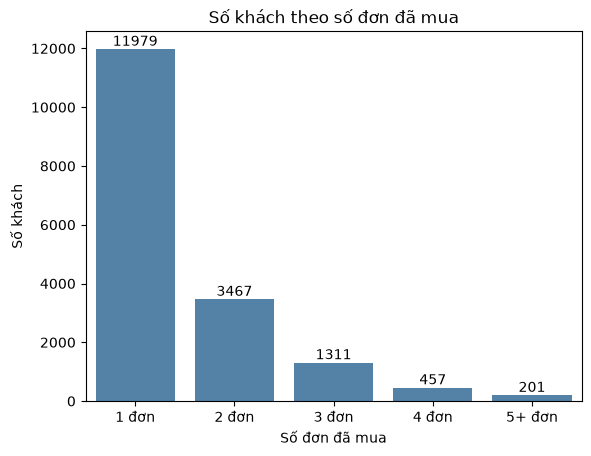

In [12]:
# Phân bố số đơn mỗi khách
freq_table = (cust['F_score'].value_counts().sort_index().to_frame('n_customers')
              .assign(pct=lambda d: (d['n_customers'] / d['n_customers'].sum() * 100).round(1)))
display(freq_table)

ax = sns.barplot(x=freq_table.index, y=freq_table['n_customers'], color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Số khách theo số đơn đã mua')
plt.xlabel('Số đơn đã mua')
plt.ylabel('Số khách')
plt.show()

**NHẬN XÉT:**
- Có 17.415 khách, 69% (11.979 khách) chỉ mua 1 đơn, 89% mua 1–2 đơn.
- Nhóm mua từ 5 đơn chỉ có 201 khách (khoảng 1%); từ 3 đơn trở lên khoảng 11%.

**INSIGHT:**
- Vấn đề lớn nhất của cửa hàng là khách không quay lại sau lần mua đầu. Các phần sau đo mức quay lại theo thời gian (cohort), tìm điểm rớt (phễu), phân nhóm khách (RFM) và đề xuất cách kéo khách lên đơn thứ hai.

# III. Phân tích cohort

- **Cohort** = quý của lần mua đầu tiên của mỗi khách.
- **quarter_after** = số quý kể từ quý mua đầu (0 = quý mua đầu).
- Giá trị = số khách **khác nhau** có mua trong quý đó; retention = số khách đó chia cho quy mô cohort.

In [13]:
cohort_df = orders.merge(cust[['CustomerID', 'first_order']], on='CustomerID')
cohort_df['first_quarter'] = cohort_df['first_order'].dt.to_period('Q')
cohort_df['quarter_after'] = ((cohort_df['OrderDate'].dt.year - cohort_df['first_order'].dt.year) * 4 +
                              (cohort_df['OrderDate'].dt.quarter - cohort_df['first_order'].dt.quarter))

cohort_counts = cohort_df.pivot_table(index='first_quarter', columns='quarter_after',
                                      values='CustomerID', aggfunc='nunique')
cohort_size = cohort_counts[0]
retention = cohort_counts.divide(cohort_size, axis=0)
retention.round(3)

quarter_after,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
first_quarter,,,,,,,,,,,,,,,,
2020Q1,1.00,0.04,0.06,0.06,0.04,0.04,0.04,0.06,0.04,0.05,0.06,0.07,0.04,0.08,0.09,0.10
2020Q2,1.00,0.04,0.05,0.03,0.04,0.06,0.07,0.04,0.06,0.06,0.09,0.05,0.07,0.09,0.09,NaN
2020Q3,1.00,0.05,0.03,0.05,0.06,0.07,0.03,0.05,0.08,0.09,0.04,0.06,0.07,0.09,NaN,NaN
2020Q4,1.00,0.04,0.04,0.05,0.08,0.04,0.06,0.07,0.07,0.04,0.08,0.07,0.11,NaN,NaN,NaN
2021Q1,1.00,0.05,0.04,0.07,0.03,0.05,0.07,0.09,0.05,0.06,0.07,0.10,NaN,NaN,NaN,NaN
2021Q2,1.00,0.05,0.07,0.03,0.05,0.06,0.07,0.04,0.06,0.07,0.10,NaN,NaN,NaN,NaN,NaN
2021Q3,1.00,0.05,0.03,0.05,0.06,0.07,0.04,0.07,0.07,0.09,NaN,NaN,NaN,NaN,NaN,NaN
2021Q4,1.00,0.04,0.05,0.06,0.07,0.05,0.06,0.07,0.09,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022Q1,1.00,0.04,0.07,0.06,0.04,0.06,0.08,0.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


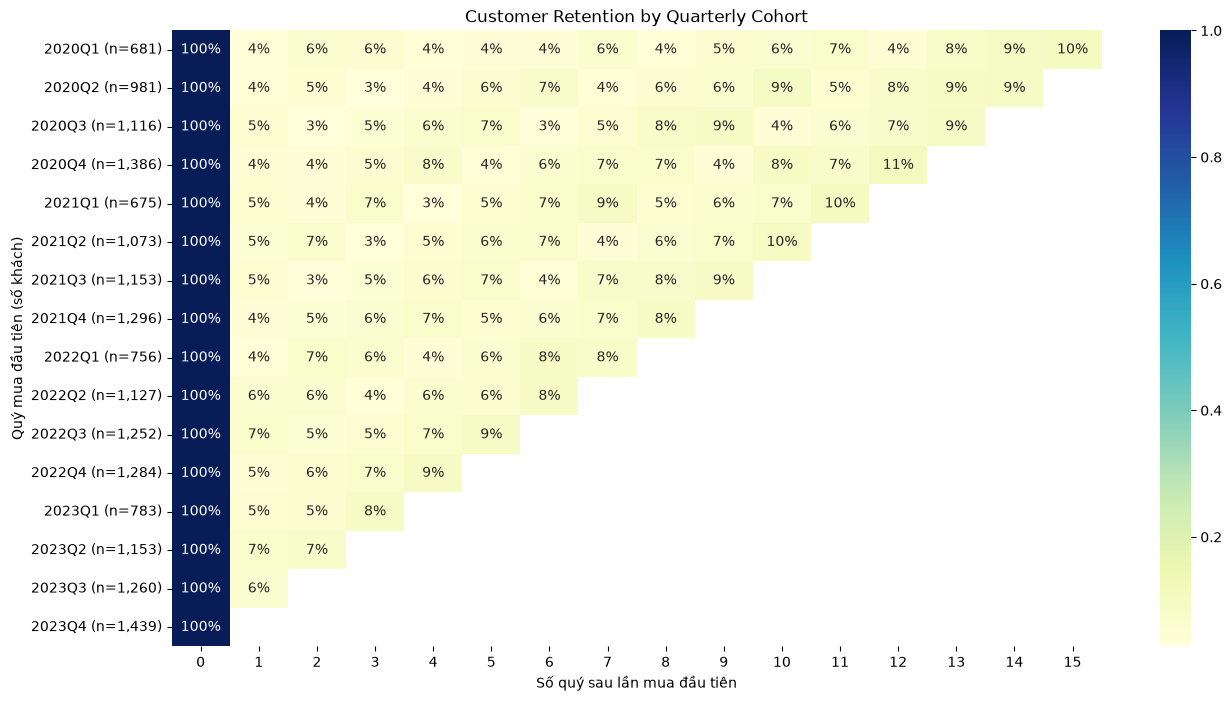

In [14]:
# Heatmap retention; số khách của mỗi cohort ghi ở nhãn trục y
labels = [f'{q} (n={int(n):,})' for q, n in cohort_size.items()]
plt.figure(figsize=(15, 8))
sns.heatmap(retention, annot=True, cmap='YlGnBu', fmt='.0%', yticklabels=labels)
plt.xlabel('Số quý sau lần mua đầu tiên')
plt.ylabel('Quý mua đầu tiên (số khách)')
plt.title('Customer Retention by Quarterly Cohort')
plt.show()

## 3.1. Quý thu hút khách hàng

**NHẬN XÉT:**
- Q1 các năm có ít khách mới nhất (ví dụ 681 khách ở 2020Q1, 675 ở 2021Q1); Q4 đông nhất (ví dụ 1.386 khách ở 2020Q4).
- Retention sau 1 quý chỉ khoảng 4–6% ở hầu hết các cohort; các quý sau dao động quanh 3–9%, không giảm đều.
- Giải thích có thể: Q1 nằm ngay sau mùa mua sắm cuối năm và Tết nên nhu cầu và ngân sách quảng cáo giảm; Q4 có các đợt giảm giá lớn (11/11, Black Friday), quà tặng cuối năm và tâm lý tự thưởng. Đây là giả thuyết, dữ liệu không có thông tin khuyến mãi hay chi phí marketing để kiểm chứng.

**INSIGHT:**
- Số khách mới tập trung ở các quý giữa và cuối năm.
- Retention của cohort Q1 tương đương các quý khác (khoảng 4–6% sau 1 quý), nên Q1 ít khách hơn nhưng khả năng quay lại không kém.

**GỢI Ý HÀNH ĐỘNG:**
- Chăm sóc sau mua cho khách mới của Q4 (nhóm đông nhất, ví dụ 1.386 khách ở 2020Q4): gửi voucher hoặc nhắc mua lại để kéo họ quay lại trong Q1.
- Thử tung sản phẩm hoặc bộ sưu tập mới vào Q1 để xem có kéo thêm khách mới không, thay vì mặc định Q1 là quý khó.
- Đo lại bằng số khách mới và retention của từng quý trước khi dịch chuyển ngân sách quảng cáo.

## 3.2. So sánh tỷ lệ quay lại giữa Corporate và Consumer

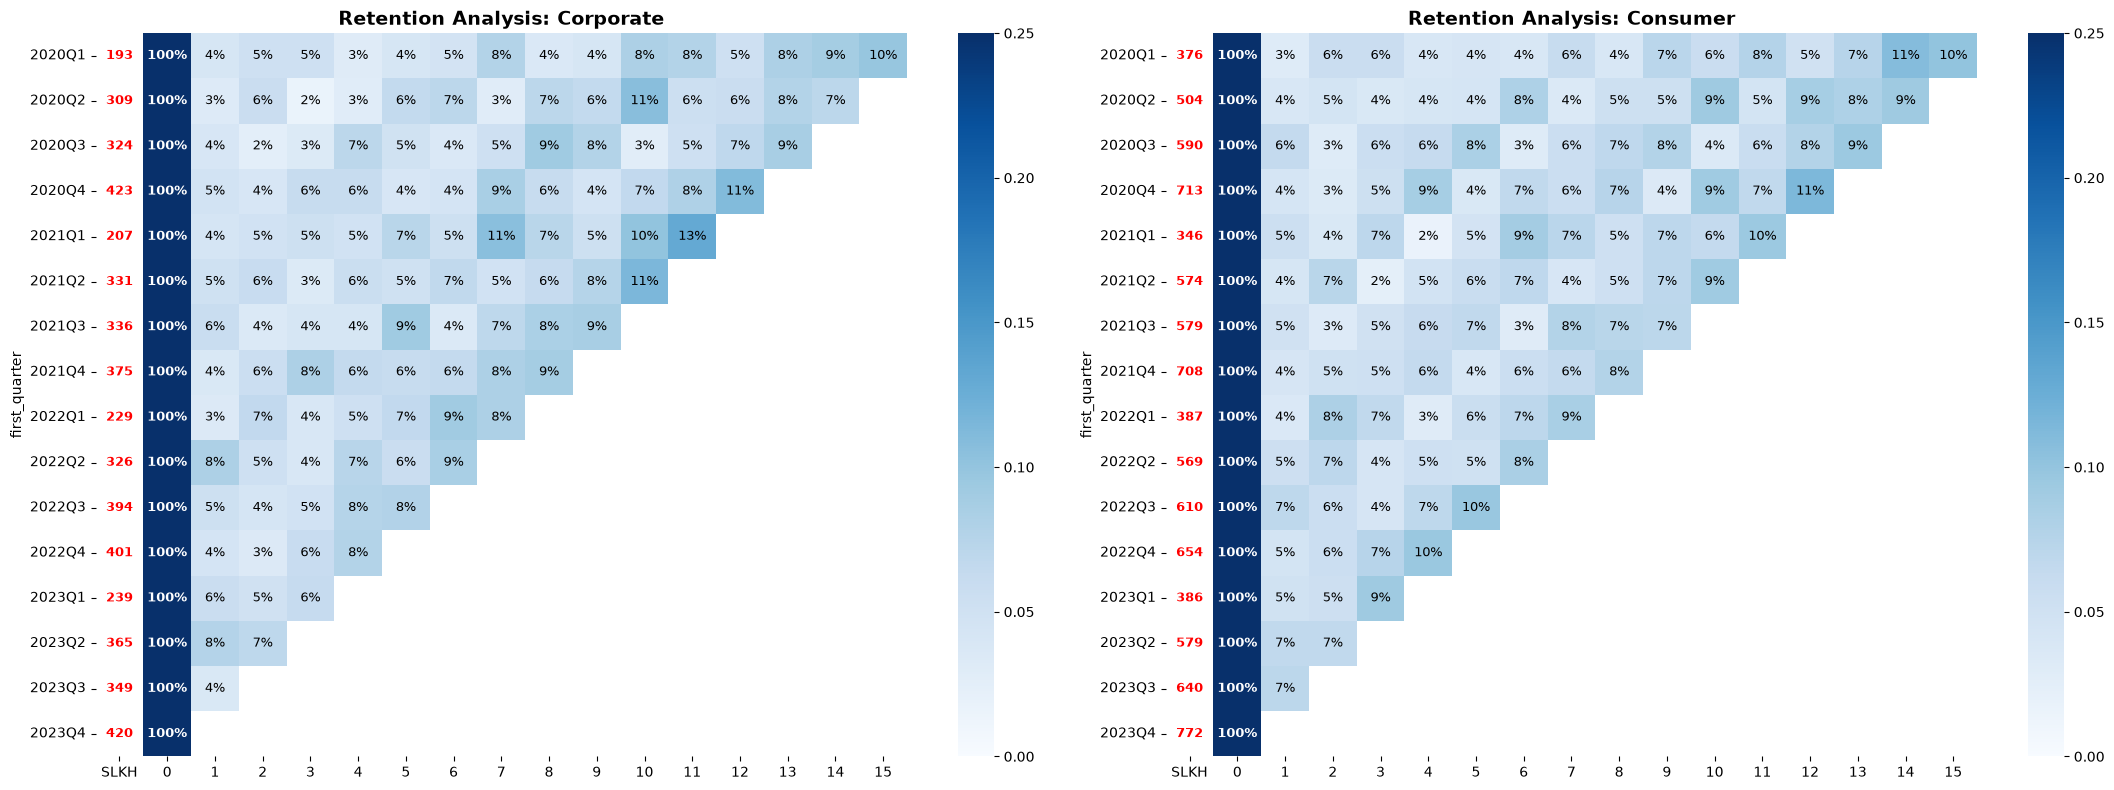

In [15]:
def plot_segment_cohort(ax, df_seg, title):
    """Vẽ heatmap retention (cột đầu = số khách của cohort) cho một Segment."""
    pivot = df_seg.pivot_table(index='first_quarter', columns='quarter_after', values='CustomerID', aggfunc='nunique')
    size = pivot.iloc[:, 0]
    ret = pivot.divide(size, axis=0)
    table = pd.concat([size.rename('SLKH'), ret], axis=1).dropna(axis=1, how='all')

    mask = np.zeros_like(table, dtype=bool)
    mask[:, 0] = True                                        # cột SLKH không tô màu
    sns.heatmap(table, annot=False, cmap='Blues', ax=ax, mask=mask, vmin=0, vmax=0.25)
    for r in range(table.shape[0]):
        for k in range(table.shape[1]):
            val = table.iloc[r, k]
            if pd.notna(val):
                color = 'red' if k == 0 else ('white' if k == 1 else 'black')
                text = f'{int(val)}' if k == 0 else f'{val:.0%}'
                ax.text(k + 0.5, r + 0.5, text, ha='center', va='center', color=color,
                        fontweight='bold' if k <= 1 else 'normal', fontsize=9)
    ax.set_title(f'Retention Analysis: {title}', fontsize=14, fontweight='bold')

fig, axes = plt.subplots(1, 2, figsize=(22, 8))
for ax, seg in zip(axes, ['Corporate', 'Consumer']):
    plot_segment_cohort(ax, cohort_df[cohort_df['Segment'] == seg], seg)
plt.tight_layout()
plt.show()

**NHẬN XÉT:** hai phân khúc có hành vi quay lại khá tương đồng.
- Corporate: mỗi cohort khoảng 190–420 khách. Tỷ lệ quay lại mỗi quý dao động quanh 3–8%, không giảm theo thời gian; ở các quý xa có cohort lên 9–13% (ví dụ 2021Q1 đạt 13% ở quý thứ 10).
- Consumer: quy mô lớn hơn (khoảng 350–770 khách mỗi cohort). Tỷ lệ quay lại cũng quanh 3–8% và nhích nhẹ lên 10–11% ở các quý xa, gần như giống Corporate.
- Chênh lệch giữa hai nhóm nhỏ (vài điểm phần trăm) và không lặp lại ổn định qua các cohort. Cohort Corporate nhỏ hơn nên số dao động nhiều hơn.

**INSIGHT:**
- Retention chưa phải yếu tố phân biệt hai segment, nên chưa thể kết luận nhóm nào trung thành hơn.
- 2023Q4 thu hút lượng khách mới lớn (772 khách Consumer, 420 khách Corporate) nhưng là quý cuối của dữ liệu nên chưa quan sát được khách quay lại.

**GỢI Ý HÀNH ĐỘNG:**
- So sánh thêm giá trị đơn hàng và lợi nhuận mỗi đơn của từng segment trước khi chọn chiến lược chăm sóc riêng.
- Chăm sóc sau mua cho khách mới của 2023Q4 và theo dõi khi dữ liệu có thêm quý.

# IV. Phễu mua lại (Repeat Purchase Funnel)

## 4.1. Phễu theo số đơn

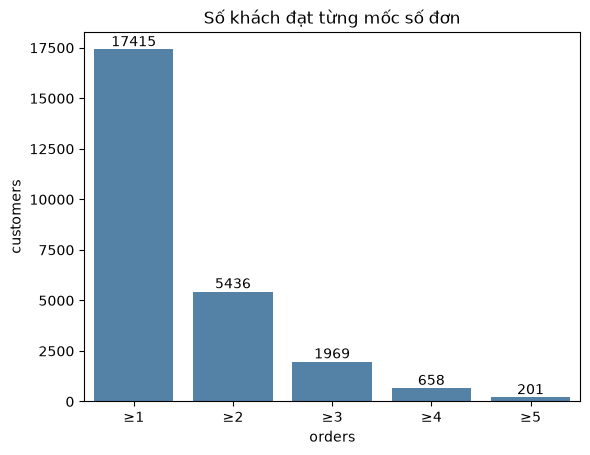

,orders,customers,pct_vs_prev,pct_vs_first
0,≥1,17415,NaN,100.00
1,≥2,5436,31.20,31.20
2,≥3,1969,36.20,11.30
3,≥4,658,33.40,3.80
4,≥5,201,30.50,1.20


In [16]:
reach = orders.groupby('CustomerID')['order_no'].max()
funnel = pd.DataFrame({'orders': ['≥1', '≥2', '≥3', '≥4', '≥5'],
                       'customers': [int((reach >= n).sum()) for n in range(1, 6)]})
funnel['pct_vs_prev'] = (funnel['customers'] / funnel['customers'].shift(1) * 100).round(1)
funnel['pct_vs_first'] = (funnel['customers'] / funnel['customers'].iloc[0] * 100).round(1)

ax = sns.barplot(x='orders', y='customers', data=funnel, color='steelblue')
ax.bar_label(ax.containers[0])
plt.title('Số khách đạt từng mốc số đơn')
plt.show()
funnel

**NHẬN XÉT:**
- Từ 17.415 khách, 5.436 khách (31%) mua đơn thứ hai, 1.969 khách (11%) mua đơn thứ ba, 658 khách (4%) mua đơn thứ tư và 201 khách (1%) mua đơn thứ năm.
- Tỷ lệ chuyển giữa các bước khá đều, quanh 30–36%: 31% (đơn 1 sang 2), 36% (2 sang 3), 33% (3 sang 4), 31% (4 sang 5).

**INSIGHT:**
- Ở mọi bước, chỉ khoảng 1 trên 3 khách mua tiếp. Không có bước nào "rớt bất thường"; đây là mức giữ chân đều ở mỗi lần mua.
- Bước đơn 1 → đơn 2 có tác động lớn nhất về số khách, vì có 17.415 khách ở bước này và mất 11.979 khách. Nâng tỷ lệ ở đây thêm vài điểm phần trăm sẽ đưa thêm nhiều khách hơn bất kỳ bước nào khác lên các đơn sau.
- Lưu ý: khách mua đơn đầu gần cuối dữ liệu chưa có đủ thời gian để mua lại, nên tỷ lệ 1 → 2 hơi thấp hơn thực tế. Phần 4.2 chỉ tính khách có đủ 12 tháng quan sát.

## 4.2. Thời gian đến đơn thứ hai

In [17]:
# Chỉ tính khách đã có ít nhất 12 tháng kể từ đơn đầu, để không đánh giá thấp tỷ lệ mua lại
first2 = (orders[orders['order_no'] <= 2]
          .pivot(index='CustomerID', columns='order_no', values='OrderDate'))
first2['gap'] = (first2[2] - first2[1]).dt.days                       # số ngày từ đơn 1 đến đơn 2 (NaN = chưa mua lại)
mature = first2[first2[1] <= orders['OrderDate'].max() - pd.Timedelta(days=365)].copy()

print(f'Khách có đủ 12 tháng quan sát: {len(mature):,}')
for d in (90, 180, 365):
    print(f'Mua đơn 2 trong {d} ngày: {(mature["gap"] <= d).mean():.1%}')
mature['gap'].describe(percentiles=[.25, .5, .75])

Khách có đủ 12 tháng quan sát: 12,780
Mua đơn 2 trong 90 ngày: 4.6%
Mua đơn 2 trong 180 ngày: 9.0%
Mua đơn 2 trong 365 ngày: 17.8%


count   4976.00
mean     460.79
std      324.72
min        0.00
25%      195.00
50%      402.00
75%      677.25
max     1451.00
Name: gap, dtype: float64

**NHẬN XÉT:**
- Chỉ tính khách mua đơn đầu đến hết 31/12/2022 (đủ 12 tháng quan sát): 12.780 khách. Trong đó 4.976 khách (39%) đã mua đơn thứ hai tính đến hết dữ liệu.
- Tỷ lệ mua đơn thứ hai cộng dồn: 4,6% trong 90 ngày, 9,0% trong 180 ngày, 17,8% trong 365 ngày.
- Với khách có mua lại, thời gian từ đơn 1 đến đơn 2 có trung vị 402 ngày; 50% khách nằm trong khoảng 195–677 ngày.

**INSIGHT:**
- Tỷ lệ mua lại tăng đều theo thời gian, không có mốc tập trung. Hơn một nửa khách mua lại là sau hơn 1 năm (402 ngày), nên khách mua lại chậm và không theo một khoảng thời gian cố định.
- Vì vậy không có "thời điểm vàng" để nhắc mua lại.

# V. Phân nhóm khách hàng bằng RFM

**Cách chấm điểm (mỗi khách 1 đến 5 điểm):**
- **R (Recency):** số ngày từ lần mua cuối đến ngày mốc (ngày cuối của dữ liệu + 1). Chia khách thành 5 phần bằng nhau; mua càng gần thì điểm càng cao (R = 5 là 20% khách mua gần nhất).
- **F (Frequency):** số đơn, chia theo số đơn thực tế (1, 2, 3, 4, 5+ đơn) vì tần suất lệch mạnh.
- **M (Monetary):** tổng doanh thu (Sales), chia 5 phần bằng nhau. M dùng để mô tả giá trị mỗi nhóm, không dùng để xếp nhóm.

**Quy tắc xếp nhóm** (xét từ trên xuống, khách khớp quy tắc nào trước thì vào nhóm đó):

| Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|
| Champions | R ≥ 4 và F ≥ 3 | Mua gần đây, từ 3 đơn |
| Loyal | F ≥ 3 (R ≤ 3) | Mua từ 3 đơn nhưng đã lâu |
| Potential Loyalist | R ≥ 4 và F = 2 | Mua gần đây, có 2 đơn |
| New Customers | R ≥ 4 và F = 1 | Mua gần đây, mới 1 đơn |
| At Risk | R ≤ 2 và F ≥ 2 | Lâu không mua, từng mua từ 2 đơn |
| About To Sleep | R = 3 và F ≤ 2 | Mua cách đây vừa phải |
| Lost | R ≤ 2 và F = 1 | Lâu không mua, chỉ 1 đơn |

*Chỉ dùng R và F để xếp nhóm vì tần suất lệch mạnh (69% khách chỉ mua 1 đơn), bảng mã RFM chuẩn 3 chữ số sẽ xếp sai nhiều khách.*

In [18]:
snapshot = orders['OrderDate'].max() + pd.Timedelta(days=1)             # ngày mốc tính Recency
rfm = cust[['CustomerID', 'Frequency', 'Monetary', 'last_order', 'F_score']].copy()
rfm['Recency'] = (snapshot - rfm['last_order']).dt.days

# rank(method='first') để chia đủ 5 nhóm kể cả khi nhiều khách có cùng giá trị
rfm['R'] = pd.qcut(rfm['Recency'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = rfm['F_score'].cat.codes + 1
rfm['M'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Gán nhóm khách theo R và F (F lệch mạnh nên không dùng bảng mã RFM 3 chữ số)
conditions = [(rfm.R >= 4) & (rfm.F >= 3),
              rfm.F >= 3,
              (rfm.R >= 4) & (rfm.F == 2),
              rfm.R >= 4,
              (rfm.R <= 2) & (rfm.F >= 2),
              rfm.R == 3]
names = ['Champions', 'Loyal', 'Potential Loyalist', 'New Customers', 'At Risk', 'About To Sleep']
rfm['Segment_RFM'] = np.select(conditions, names, default='Lost')

seg = (rfm.groupby('Segment_RFM')
          .agg(n_customers=('CustomerID', 'count'), revenue=('Monetary', 'sum'),
               avg_recency=('Recency', 'mean'), avg_orders=('Frequency', 'mean'), avg_spend=('Monetary', 'mean')))
seg['pct_customers'] = (seg['n_customers'] / seg['n_customers'].sum() * 100).round(1)
seg['pct_revenue'] = (seg['revenue'] / seg['revenue'].sum() * 100).round(1)
seg = seg.sort_values('revenue', ascending=False)
seg.round(1)

,n_customers,revenue,avg_recency,avg_orders,avg_spend,pct_customers,pct_revenue
Segment_RFM,,,,,,,
Lost,5929,1486793,953.20,1.00,250.80,34.00,22.80
Champions,1395,1240222,107.80,3.50,889.00,8.00,19.00
About To Sleep,3101,991490,427.70,1.30,319.70,17.80,15.20
Potential Loyalist,1816,937804,127.10,2.00,516.40,10.40,14.40
New Customers,3755,912889,132.70,1.00,243.10,21.60,14.00
Loyal,574,536075,519.40,3.30,933.90,3.30,8.20
At Risk,845,412401,820.40,2.00,488.00,4.90,6.30


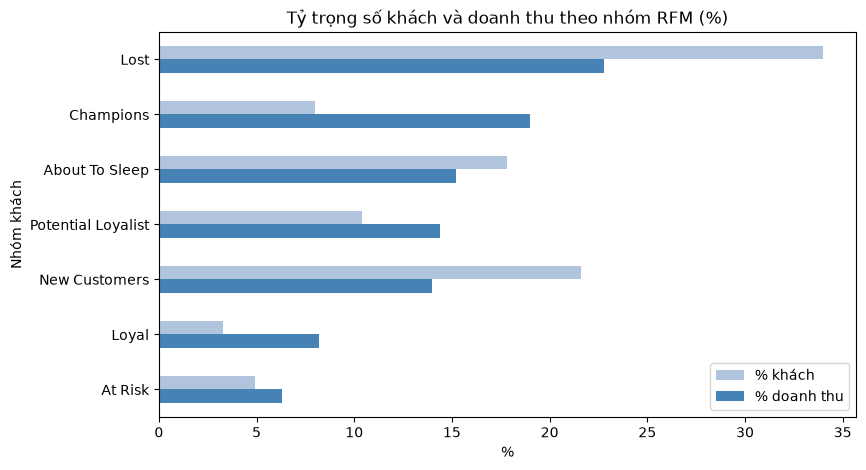

In [19]:
seg[['pct_customers', 'pct_revenue']].plot(kind='barh', figsize=(9, 5), color=['lightsteelblue', 'steelblue'])
plt.title('Tỷ trọng số khách và doanh thu theo nhóm RFM (%)')
plt.xlabel('%')
plt.ylabel('Nhóm khách')
plt.legend(['% khách', '% doanh thu'])
plt.gca().invert_yaxis()
plt.show()

**NHẬN XÉT:**
- Nhóm đông khách nhất là Lost (5.929 khách, 34,0%) và cũng là nhóm đóng góp doanh thu lớn nhất (22,8%), nhưng mỗi khách chỉ chi trung bình khoảng 251 và mua 1 đơn.
- Champions chỉ chiếm 8,0% khách nhưng đóng góp 19,0% doanh thu (chi trung bình 889, 3,5 đơn, mua gần nhất cách khoảng 108 ngày). Cùng với Loyal (3,3% khách, 8,2% doanh thu), hai nhóm này chiếm 11,3% khách nhưng 27,2% doanh thu.
- Loyal mua nhiều (3,3 đơn) nhưng đã lâu chưa quay lại (trung bình khoảng 519 ngày), khác hẳn Champions (108 ngày).
- At Risk và Lost (đã lâu không mua) chiếm 38,9% khách và 29,1% doanh thu.
- New Customers (1 đơn, mua gần đây) chiếm 21,6% khách; Potential Loyalist (2 đơn, mua gần đây) chiếm 10,4%.

**INSIGHT:**
- Doanh thu tập trung ở nhóm nhỏ: khoảng 11% khách (Champions và Loyal) tạo ra 27% doanh thu, nên cần giữ chân nhóm này.
- New Customers và Potential Loyalist (khoảng 32% khách) vừa mua gần đây, là nhóm có cơ hội cao nhất để kéo lên đơn kế tiếp.
- Lost chiếm 1/3 khách nhưng chi tiêu thấp và đã lâu không mua, nên không nên đầu tư nhiều.

**GỢI Ý HÀNH ĐỘNG (giả thuyết, cần thử nghiệm):**
1. **Champions (1.395 khách):** giữ chân bằng ưu đãi sớm hoặc tích điểm. Họ đã mua đều nên không cần giảm giá sâu.
2. **Loyal (574 khách):** đây là khách từng mua nhiều nhưng đã lâu không quay lại (khoảng 519 ngày). Gửi chiến dịch kéo quay lại, vì chi phí tiếp cận thấp mà khả năng đáp ứng có thể cao hơn khách mới.
3. **New Customers và Potential Loyalist (5.571 khách):** nhóm mua gần đây, gửi ưu đãi cho đơn kế tiếp. Đây là nhóm phù hợp nhất để thử A/B test voucher ở phần VII.
4. **At Risk và About To Sleep (3.946 khách):** nhắc nhở hoặc ưu đãi trước khi họ trở thành Lost.
5. **Lost (5.929 khách):** chỉ dùng kênh chi phí thấp (email), tránh đầu tư nhiều.


# VI. Đặc điểm khách mua nhiều lần

## 6.1. Tổng hợp theo số đơn đã mua

,n_customers,n_orders,avg_sales_per_order,avg_profit_per_order,avg_discount,profit_margin_pct
F_score,,,,,,
1 đơn,11979,11979,248.64,38.75,0.15,15.59
2 đơn,3467,6934,254.24,40.25,0.15,15.83
3 đơn,1311,3933,255.41,44.76,0.13,17.52
4 đơn,457,1828,244.96,46.81,0.12,19.11
5+ đơn,201,1065,304.19,56.83,0.12,18.68


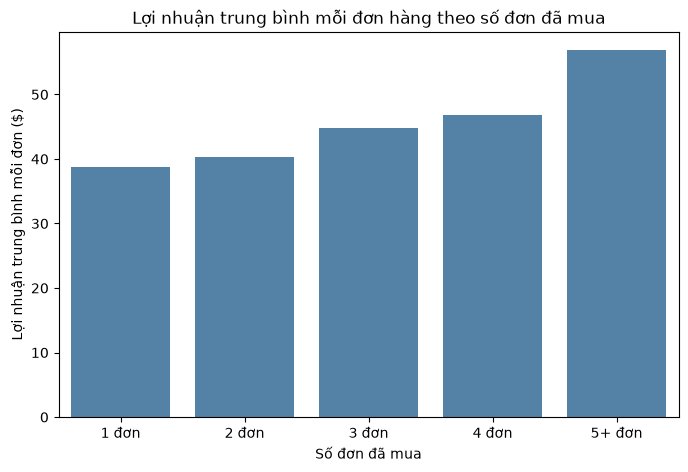

In [20]:
profile = (orders.merge(cust[['CustomerID', 'F_score']], on='CustomerID')
           .groupby('F_score', observed=True)
           .agg(n_customers=('CustomerID', 'nunique'), n_orders=('OrderID', 'count'),
                avg_sales_per_order=('Sales', 'mean'), avg_profit_per_order=('Profit', 'mean'),
                avg_discount=('Discount', 'mean'))
           .assign(profit_margin_pct=lambda d: d['avg_profit_per_order'] / d['avg_sales_per_order'] * 100)
           .round(2))
display(profile)

plt.figure(figsize=(8, 5))
sns.barplot(x=profile.index, y=profile['avg_profit_per_order'], color='steelblue')
plt.title('Lợi nhuận trung bình mỗi đơn hàng theo số đơn đã mua')
plt.xlabel('Số đơn đã mua')
plt.ylabel('Lợi nhuận trung bình mỗi đơn ($)')
plt.show()

**NHẬN XÉT:**
- Lợi nhuận trung bình mỗi đơn tăng theo số đơn đã mua: 1 đơn ≈ 38,8; 2 đơn ≈ 40,3; 3 đơn ≈ 44,8; 4 đơn ≈ 46,8; 5+ đơn ≈ 56,8.
- Doanh thu mỗi đơn gần như không đổi ở nhóm 1–4 đơn (khoảng 245–255); chỉ nhóm 5+ đơn cao hẳn lên (304,2, cao hơn nhóm 1 đơn khoảng 22%).
- Mức giảm giá trung bình giảm dần theo số đơn: 15% (1–2 đơn), 13% (3 đơn), 12% (4 đơn trở lên).
- Ở nhóm 1–4 đơn, doanh thu mỗi đơn gần như không đổi nhưng lợi nhuận vẫn tăng (tỷ suất lợi nhuận tăng từ 15,6% lên 19,1%), đi cùng với mức giảm giá thấp hơn. Ở nhóm 5+ đơn, lợi nhuận cao hơn nhờ cả đơn lớn hơn lẫn giảm giá thấp hơn.
- Lưu ý: nhóm 5+ đơn chỉ có 201 khách (1.065 đơn), cần thận trọng khi kết luận.

**INSIGHT:**
- Khách mua nhiều lần không được giảm giá nhiều hơn khách mua một lần (mức giảm giá trung bình thấp hơn: 12% so với 15%), nên việc họ quay lại nhiều khả năng không chỉ nhờ giảm giá. Đây là mối liên hệ trong dữ liệu, chưa chứng minh nguyên nhân; muốn biết ưu đãi có làm khách mua lại hay không cần A/B test (phần VII).

## 6.2. Thu nhập theo số đơn đã mua

  F_score  AnnualIncome
0   1 đơn      57968.11
1   2 đơn      55067.78
2   3 đơn      56430.21
3   4 đơn      55929.98
4  5+ đơn      55323.38


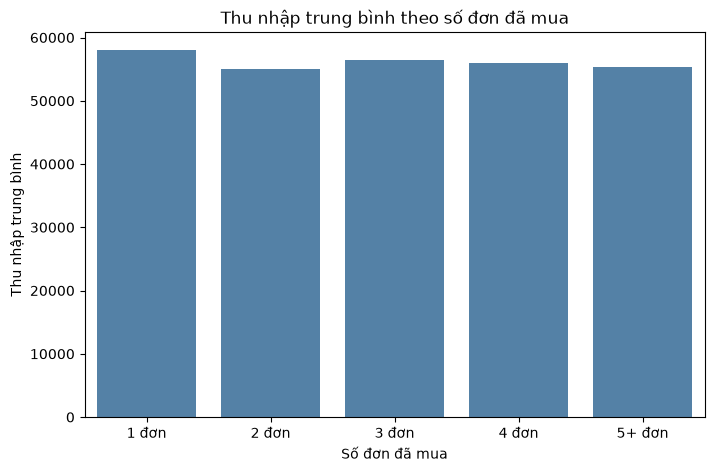

In [21]:
income_by_f = (cust.merge(customers[['CustomerID', 'AnnualIncome']], on='CustomerID', how='left')
                   .groupby('F_score', observed=True)['AnnualIncome'].mean().reset_index())
print(income_by_f)

plt.figure(figsize=(8, 5))
sns.barplot(x='F_score', y='AnnualIncome', data=income_by_f, color='steelblue')
plt.title('Thu nhập trung bình theo số đơn đã mua')
plt.xlabel('Số đơn đã mua')
plt.ylabel('Thu nhập trung bình')
plt.show()

**NHẬN XÉT:**
- Thu nhập trung bình chỉ dao động trong khoảng hẹp 55.000–58.000 ở cả 5 nhóm, không tăng theo số đơn đã mua.
- Nhóm mua 1 đơn có thu nhập nhỉnh nhất (57.968), cao hơn nhóm 5+ đơn (55.323) khoảng 5%. Chênh lệch này nhỏ, và nhóm 5+ đơn chỉ có 201 khách nên chưa đủ để kết luận.

**INSIGHT:**
- Thu nhập không giúp dự đoán ai sẽ mua nhiều lần: khách ở mọi mức thu nhập đều có thể quay lại. Vì vậy không nên chọn đối tượng chăm sóc hay ưu đãi theo thu nhập, mà nên dựa vào hành vi mua.
- Cơ hội lớn nằm ở số đông: 89% khách chỉ mua 1–2 đơn, trong khi nhóm mua từ 5 đơn chỉ khoảng 1%. Kéo khách từ đơn thứ nhất lên đơn thứ hai (voucher, nhắc mua lại) có tác động lớn hơn việc chỉ chăm sóc nhóm khách mua nhiều.

## 6.3. Danh mục sản phẩm

Category
Body care               142553
Home and Accessories     43058
Hair care                38016
Make up                  36919
Face care                17232
Name: Quantity, dtype: int64


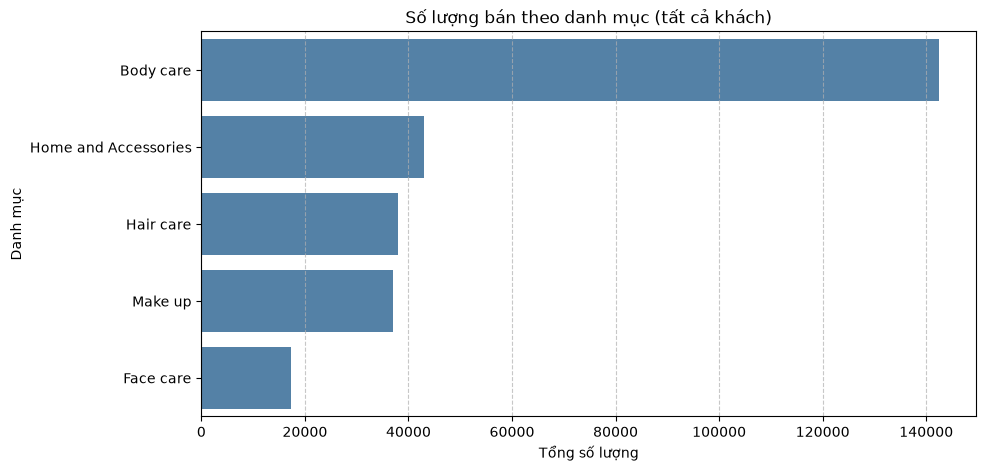

In [22]:
# Số lượng bán theo danh mục (tất cả khách)
sold_by_cat = df.groupby('Category')['Quantity'].sum().sort_values(ascending=False)
print(sold_by_cat)

plt.figure(figsize=(10, 5))
sns.barplot(x=sold_by_cat.values, y=sold_by_cat.index, color='steelblue')
plt.title('Số lượng bán theo danh mục (tất cả khách)')
plt.xlabel('Tổng số lượng')
plt.ylabel('Danh mục')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Category
Body care               64435
Home and Accessories    19536
Hair care               17502
Make up                 17356
Face care                8031
Name: Quantity, dtype: int64


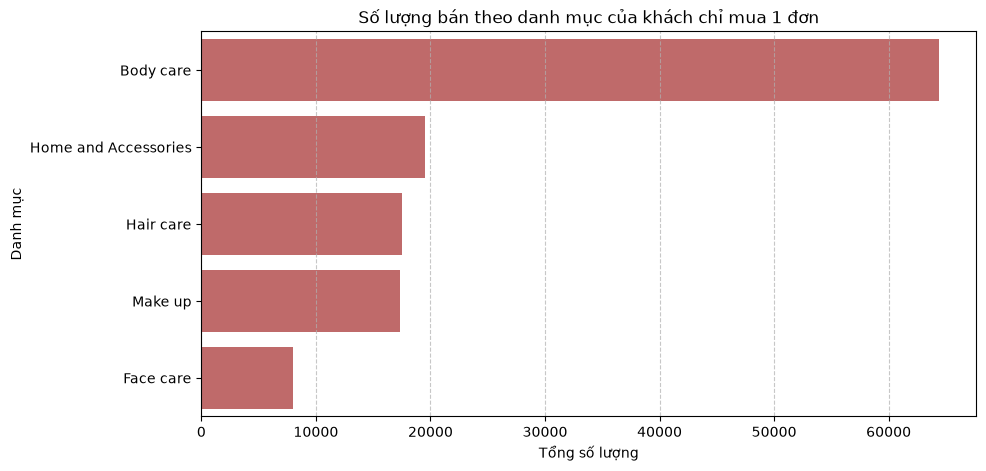

In [23]:
# Số lượng bán theo danh mục của khách chỉ mua 1 đơn
one_time_ids = cust.loc[cust['Frequency'] == 1, 'CustomerID']
one_time_cat = (df[df['CustomerID'].isin(one_time_ids)]
                .groupby('Category')['Quantity'].sum().sort_values(ascending=False))
print(one_time_cat)

plt.figure(figsize=(10, 5))
sns.barplot(x=one_time_cat.values, y=one_time_cat.index, color='indianred')
plt.title('Số lượng bán theo danh mục của khách chỉ mua 1 đơn')
plt.xlabel('Tổng số lượng')
plt.ylabel('Danh mục')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

**NHẬN XÉT:**
- Body care là danh mục bán chạy nhất với 142.553 sản phẩm, chiếm 51,3% tổng số lượng bán và gấp hơn 3 lần danh mục đứng thứ hai (Home and Accessories, 15,5%). Face care bán ít nhất (6,2%).
- Ở nhóm khách chỉ mua 1 đơn, thứ tự và tỷ trọng các danh mục gần như giống hệt toàn bộ khách: Body care chiếm 50,8%, các danh mục khác chênh lệch không quá 0,4 điểm phần trăm.
- Khách chỉ mua 1 đơn chiếm khoảng 69% số khách nhưng chỉ tạo ra 45,7% số lượng bán.

**INSIGHT:**
- Body care là danh mục chủ lực về số lượng với mọi nhóm khách. Khách mua 1 lần không mua khác với khách quay lại, nên chỉ dựa vào danh mục thì chưa phân biệt được ai sẽ quay lại.
- Biểu đồ này đo số lượng, chưa phải doanh thu. Body care bán nhiều nhưng có thể có đơn giá thấp, nên cần xem thêm tỷ trọng doanh thu trước khi kết luận đây là danh mục mang lại nhiều giá trị nhất.

Category
Face care              24.30
Make up                21.50
Hair care              21.00
Home and Accessories   20.70
Body care              14.70
Name: CustomerID, dtype: float64


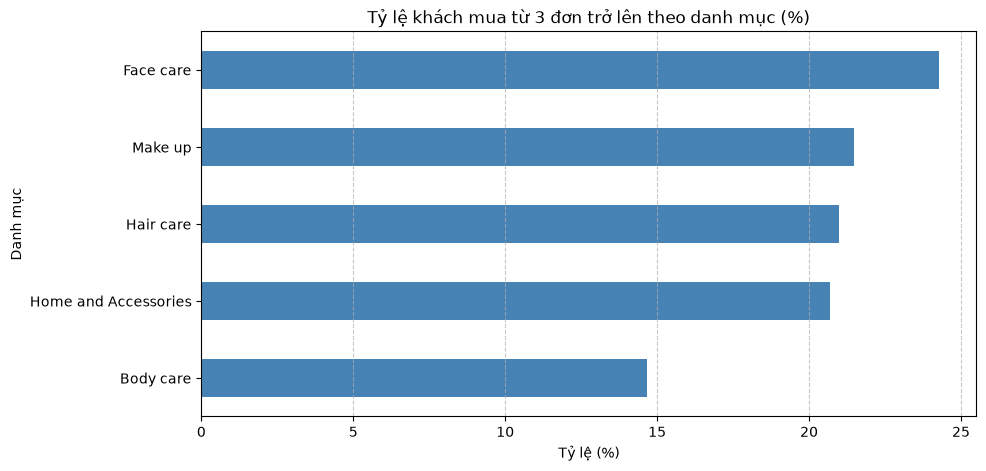

In [24]:
# Tỷ lệ khách mua từ 3 đơn trở lên trong mỗi danh mục
loyal_ids = cust.loc[cust['Frequency'] >= 3, 'CustomerID']
customers_by_cat = df.groupby('Category')['CustomerID'].nunique()
loyal_by_cat = df[df['CustomerID'].isin(loyal_ids)].groupby('Category')['CustomerID'].nunique()
loyal_rate = (loyal_by_cat / customers_by_cat * 100).sort_values(ascending=False)
print(loyal_rate.round(1))

plt.figure(figsize=(10, 5))
loyal_rate.plot(kind='barh', color='steelblue')
plt.title('Tỷ lệ khách mua từ 3 đơn trở lên theo danh mục (%)')
plt.xlabel('Tỷ lệ (%)')
plt.ylabel('Danh mục')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.gca().invert_yaxis()
plt.show()

**NHẬN XÉT:**
- Face care có tỷ lệ khách mua từ 3 đơn trở lên cao nhất (khoảng 24%), nhỉnh hơn Make up, Hair care và Home and Accessories (khoảng 21%). Điều này gợi ý khách mua chăm sóc da mặt có xu hướng quay lại nhiều hơn một chút.
- Body care thấp nhất (khoảng 15%), thấp hơn rõ so với các danh mục còn lại.
- Lưu ý: khách mua nhiều đơn thường mua nhiều danh mục, nên chênh lệch giữa 4 danh mục đầu khá nhỏ và cần thận trọng khi kết luận.
- Lưu ý: Body care có nhiều khách mua nhất, gồm cả rất nhiều khách chỉ mua 1 lần, nên tỷ lệ khách 3+ đơn bị kéo thấp xuống. Ngược lại, khách mua nhiều đơn thường mua nhiều danh mục nên chiếm phần lớn hơn ở danh mục nhỏ như Face care. Vì vậy chênh lệch tỷ lệ giữa các danh mục phản ánh độ phủ khách nhiều hơn là khả năng giữ chân khách của từng danh mục.

**INSIGHT:**
- Face care có thể là sản phẩm đòi hỏi sự tin tưởng nên khách ít đổi và quay lại mua tiếp. Đây là giả thuyết cần kiểm chứng.

**GỢI Ý HÀNH ĐỘNG:**
- Thử chiến lược "Upsell từ Face care": ưu tiên quảng cáo chăm sóc da mặt cho khách mới, rồi đo xem tỷ lệ mua đơn thứ hai có tăng không.
- Với khách mua Body care, gửi khuyến mãi hoặc email hướng dẫn dùng/review để tăng khả năng quay lại.
- Kiểm tra vì sao Body care thấp: nếu do đặc thù sản phẩm ít cần mua lại thì không cần lo; nếu do chất lượng thì xem lại nguồn hàng.

# VII. Thiết kế A/B test: voucher cho đơn thứ hai

Các phần trên chỉ cho thấy **mối liên hệ** trong dữ liệu quá khứ, ví dụ khách mua nhiều đơn lại được giảm giá ít hơn. Muốn biết ưu đãi có thật sự **làm** khách mua lại hay không, cần một thí nghiệm có nhóm đối chứng: chia khách **ngẫu nhiên** thành hai nhóm, một nhóm nhận voucher, một nhóm không. Vì chia ngẫu nhiên nên hai nhóm giống nhau ở mọi mặt khác, và chênh lệch về tỷ lệ mua lại có thể quy cho voucher.

Bộ dữ liệu mẫu không có thí nghiệm nào, nên phần này chỉ **thiết kế** thí nghiệm, chưa chạy.

**Vì sao chọn bước mua đơn thứ hai:** phễu ở phần IV cho thấy bước từ đơn 1 sang đơn 2 mất nhiều khách nhất về số lượng (khoảng 69% khách chỉ mua 1 đơn). Cải thiện được bước này sẽ có tác động lớn nhất.

| Mục | Nội dung |
|---|---|
| Giả thuyết | Khách vừa mua đơn đầu và nhận voucher có tỷ lệ mua đơn thứ hai trong 90 ngày cao hơn khách không nhận |
| Đối tượng | Khách mới vừa hoàn tất đơn đầu tiên |
| Phân nhóm | Ngẫu nhiên 50/50: nhóm A (control, không voucher) và nhóm B (nhận voucher) |
| Chỉ số chính | Tỷ lệ khách mua đơn thứ hai trong 90 ngày sau đơn đầu |
| Chỉ số phụ | Lợi nhuận mỗi đơn thứ hai sau khi trừ voucher, giá trị đơn |
| Mức voucher | So sánh 3 phương án: 5, 10 và 15 USD (giải thích bên dưới) |
| Cỡ mẫu và thời gian | Tính ở ô code bên dưới |
| Tiêu chí quyết định | Triển khai nếu tỷ lệ của nhóm B cao hơn nhóm A có ý nghĩa thống kê (p < 0,05) **và** cao hơn tỷ lệ hòa vốn của mức voucher đã chọn |

### Cách tính

Thiết kế đi qua 5 bước: (1) xác định tỷ lệ mua lại hiện tại → (2) tính tỷ lệ cần đạt để voucher hòa vốn với từng mức 5, 10, 15 USD → (3) từ đó suy ra mức tăng cần phát hiện (MDE) → (4) tính số khách cần cho mỗi nhóm → (5) đổi số khách ra thời gian chạy, để chọn mức voucher khả thi.

**1. Tỷ lệ gốc (p₀)**

Tỷ lệ gốc là tỷ lệ mua lại khi **chưa có voucher**. Trong 12.780 khách đã đủ 1 năm quan sát (phần 4.2), khoảng **4,6%** mua đơn thứ hai trong vòng 90 ngày. Đây là kết quả dự kiến của nhóm A, đồng thời là mốc để đo mức tăng.

**2. Vì sao chọn 3 mức voucher 5, 10 và 15 USD**

- Giá trị đơn trung bình khoảng 250 USD (phần 6.1), nên 3 mức này tương ứng khoảng **2%, 4% và 6%** giá trị đơn, đại diện cho mức ưu đãi nhỏ, vừa và lớn.
- Lợi nhuận trung bình mỗi đơn khoảng 40 USD. Voucher phải nhỏ hơn con số này, nếu không thì đơn nào dùng voucher cũng lỗ.
- Đây là các mức giả định để so sánh. Trong thực tế, doanh nghiệp sẽ chọn theo ngân sách khuyến mãi.

**3. Tỷ lệ hòa vốn và MDE**

Voucher được trả cho **mọi** khách nhóm B mua đơn thứ hai, kể cả những người đằng nào cũng sẽ mua. Vì vậy nhóm B chỉ có lãi hơn nhóm A khi:

$$p_1 \times (P - V) \ge p_0 \times P \quad\Rightarrow\quad p_1 \ge \frac{p_0 \times P}{P - V}$$

$$MDE = p_1 - p_0$$

Trong đó: P là lợi nhuận trung bình mỗi đơn, V là giá trị voucher, p₁ là tỷ lệ hòa vốn của nhóm B.

*Ví dụ với 1.000 khách mỗi nhóm, P = 40, V = 10:* nhóm A có 46 khách mua lại (4,6%), lời 46 × 40 = 1.840 USD. Ở nhóm B, mỗi đơn chỉ còn lời 40 − 10 = 30 USD, nên cần 1.840 ÷ 30 ≈ 61 khách, tức **6,1%**. MDE = 6,1% − 4,6% = **1,5 điểm phần trăm**, tương đương tăng khoảng 33% so với tỷ lệ gốc.

**MDE (Minimum Detectable Effect)** là mức tăng nhỏ nhất mà thí nghiệm cần phát hiện được. Nếu voucher chỉ giúp tăng ít hơn mức hòa vốn thì dù phát hiện ra cũng không nên triển khai, nên MDE được chọn bằng đúng mức hòa vốn.

**4. Cỡ mẫu**

Dùng hai thông số theo quy ước chung:
- **alpha = 0,05:** chấp nhận tối đa 5% rủi ro "báo động giả", tức kết luận voucher có tác dụng trong khi thật ra không có. Sau khi chạy thí nghiệm, p-value sẽ được so với ngưỡng này.
- **power = 0,8:** nếu voucher thật sự giúp tăng ít nhất bằng MDE, thí nghiệm có 80% khả năng phát hiện ra. Power chỉ dùng để tính cỡ mẫu.

Số khách cần cho **mỗi nhóm**:

$$n = \frac{(1{,}96 + 0{,}84)^2 \times \big[p_0(1-p_0) + p_1(1-p_1)\big]}{(p_1 - p_0)^2}$$

- **(1,96 + 0,84)²:** mức chắc chắn yêu cầu (1,96 ứng với alpha = 0,05; 0,84 ứng với power = 0,8).
- **Tử số:** mức dao động ngẫu nhiên tự nhiên của tỷ lệ mua lại.
- **Mẫu số:** bình phương mức tăng cần phát hiện (MDE). Mức tăng càng nhỏ thì cần càng nhiều khách: giảm MDE một nửa thì cần khoảng gấp 4 lần số khách.

*Ví dụ voucher 10 USD:* n = 7,85 × (0,0464 × 0,9536 + 0,0612 × 0,9388) ÷ 0,0148² ≈ **3.640 khách mỗi nhóm** (code tính ra 3.641). Hàm `NormalIndPower` trong code dùng công thức tương đương.

**5. Thời gian chạy**

$$\text{Thời gian chạy} = \frac{2 \times n}{\text{số khách mới mỗi quý}} + \text{thời gian theo dõi}$$

- **2 × n:** tổng số khách của cả hai nhóm.
- **Số khách mới mỗi quý:** chỉ khách mới mới tham gia được thí nghiệm. Trung bình mỗi quý có khoảng **1.088 khách mới** (17.415 khách ÷ 16 quý).
- **Thời gian theo dõi:** khách cuối cùng vào thí nghiệm phải được theo dõi thêm 90 ngày (khoảng **1 quý**) để biết họ có mua đơn thứ hai không.

*Ví dụ voucher 10 USD:* 2 × 3.641 ÷ 1.088 ≈ 6,7 quý gom khách, cộng 1 quý theo dõi, tổng khoảng **7,7 quý (gần 2 năm)**.

In [28]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

p0 = (mature['gap'] <= 90).mean()              # tỷ lệ gốc: mua đơn 2 trong 90 ngày
profit_per_order = orders['Profit'].mean()     # lợi nhuận trung bình mỗi đơn
new_per_quarter = cohort_size.mean()           # số khách mới trung bình mỗi quý

scenarios = pd.DataFrame({'voucher': [5, 10, 15]})
scenarios['breakeven_rate'] = p0 * profit_per_order / (profit_per_order - scenarios['voucher'])
scenarios['mde'] = scenarios['breakeven_rate'] - p0
scenarios['relative_lift_pct'] = scenarios['mde'] / p0 * 100
scenarios['n_per_group'] = [int(np.ceil(NormalIndPower().solve_power(proportion_effectsize(p1, p0), alpha=0.05, power=0.8, ratio=1)))
                            for p1 in scenarios['breakeven_rate']]
scenarios['quarters_needed'] = 2 * scenarios['n_per_group'] / new_per_quarter
scenarios['total_quarters'] = scenarios['quarters_needed'] + 1   # + 90 ngày theo dõi

print(f'Tỷ lệ gốc: {p0:.1%} | Lợi nhuận TB mỗi đơn: ${profit_per_order:.1f} | Khách mới TB mỗi quý: {new_per_quarter:,.0f}')
display(scenarios.assign(breakeven_rate=scenarios['breakeven_rate'] * 100, mde=scenarios['mde'] * 100)
        .rename(columns={'breakeven_rate': 'breakeven_rate_pct', 'mde': 'mde_pp'}).round(2))

Tỷ lệ gốc: 4.6% | Lợi nhuận TB mỗi đơn: $41.4 | Khách mới TB mỗi quý: 1,088


,voucher,breakeven_rate_pct,mde_pp,relative_lift_pct,n_per_group,quarters_needed,total_quarters
0,5,5.28,0.64,13.74,18187,33.42,34.42
1,10,6.12,1.48,31.85,3641,6.69,7.69
2,15,7.28,2.64,56.83,1250,2.30,3.30


**NHẬN XÉT:**
- Tỷ lệ gốc khoảng 4,6%, lợi nhuận trung bình mỗi đơn khoảng 41,4. Voucher càng lớn thì tỷ lệ cần đạt để hòa vốn càng cao: 5,3% (5 USD), 6,1% (10 USD) và 7,3% (15 USD).
- Voucher 5 USD chỉ cần tăng 0,6 điểm phần trăm nhưng cần tới 18.187 khách mỗi nhóm, tức khoảng 34 quý. Thời gian này quá dài nên không khả thi.
- Voucher 15 USD chỉ cần 1.250 khách mỗi nhóm (khoảng 3,3 quý), nhưng tỷ lệ mua lại phải tăng 2,6 điểm phần trăm (tăng khoảng 57%) mới hòa vốn.
- Voucher 10 USD nằm ở giữa: cần tăng 1,5 điểm phần trăm (khoảng 32%) và 3.641 khách mỗi nhóm (khoảng 7,7 quý).
- Lưu ý: kết quả chỉ có ý nghĩa nếu khách được chia ngẫu nhiên và không có thay đổi nào khác (giá, chương trình khuyến mãi khác) trong thời gian thử nghiệm.

**INSIGHT:**
- Voucher nhỏ dễ hòa vốn nhưng khó đo, voucher lớn dễ đo nhưng khó có lãi. Điều này cho thấy mức voucher cần được chọn dựa trên cả chi phí lẫn thời gian thử nghiệm, không chỉ dựa vào mức ưu đãi.
- Với khoảng 1.088 khách mới mỗi quý, chỉ voucher 15 USD cho kết quả trong vòng 1 năm. Tỷ lệ gốc thấp (dưới 5%) và lượng khách mới hạn chế là giới hạn chính khi thử nghiệm trên bộ dữ liệu mẫu này.

**GỢI Ý HÀNH ĐỘNG:**
- Thử trước voucher 15 USD vì cho kết quả nhanh nhất (khoảng 10 tháng). Nếu tỷ lệ nhóm B vượt 7,3% thì triển khai; nếu cao hơn nhóm A nhưng chưa tới mức hòa vốn thì thử tiếp mức voucher thấp hơn.
- Đo lại bằng lợi nhuận sau khi trừ voucher, không chỉ bằng tỷ lệ mua lại, trước khi triển khai rộng.

# VIII. Kết luận, đề xuất và giới hạn dữ liệu

## 8.1. Phát hiện chính
1. **Khách ít quay lại:** 69% khách (11.979 khách) chỉ mua 1 đơn, chỉ 31% mua đơn thứ hai. Mỗi quý chỉ khoảng 4–8% khách của một cohort mua lại.
2. **Bước từ đơn 1 sang đơn 2 mất nhiều khách nhất về số lượng** (gần 12.000 khách). Từ đơn 2 trở đi, mỗi bước giữ lại khoảng 1/3 số khách (31–36%).
3. **Khách quay lại chậm:** trong nhóm khách có đủ 12 tháng quan sát, chỉ 4,6% mua đơn thứ hai trong 90 ngày, 9,0% trong 180 ngày và 17,8% trong 365 ngày. Thời gian trung vị đến đơn thứ hai là 402 ngày, nghĩa là hơn một nửa khách mua lại quay lại sau hơn 1 năm.
4. **Segment và thu nhập không phân biệt được khách mua lại:** Corporate và Consumer quay lại tương đương nhau; thu nhập trung bình các nhóm số đơn gần như bằng nhau (55.000–58.000).
5. **Doanh thu tập trung ở nhóm nhỏ (RFM):** Champions và Loyal chỉ chiếm 11,3% khách nhưng tạo ra 27,2% doanh thu. New Customers và Potential Loyalist (khoảng 32% khách) vừa mua gần đây, là nhóm có cơ hội cao nhất để kéo lên đơn tiếp theo.
6. **Khách mua nhiều lần có lợi nhuận mỗi đơn cao hơn** (khoảng 56,8 so với 38,8) dù được giảm giá ít hơn (12% so với 15%).
7. **Danh mục:** Body care chiếm 51,3% số lượng bán ở mọi nhóm khách. Face care có tỷ lệ khách mua từ 3 đơn trở lên cao nhất (khoảng 24%, Body care khoảng 15%), nhưng chênh lệch này phản ánh độ phủ khách của danh mục nhiều hơn là khả năng giữ chân khách.

## 8.2. Đề xuất
1. Tập trung kéo khách từ đơn 1 lên đơn 2 bằng nhắc mua lại hoặc voucher, vì đây là bước mất nhiều khách nhất và khách thường quay lại rất chậm.
2. Kiểm chứng ưu đãi bằng A/B test trước khi áp dụng rộng (phần VII). Thử trước voucher 15 USD vì cho kết quả nhanh nhất (khoảng 10 tháng); chỉ triển khai khi tỷ lệ mua lại vượt mức hòa vốn 7,3%.
3. Chọn đối tượng ưu đãi theo hành vi mua (RFM), không theo thu nhập hay Segment: giữ chân Champions, kéo New Customers và Potential Loyalist lên đơn tiếp theo, chỉ dùng chiến dịch chi phí thấp cho nhóm Lost.
4. Thử Face care làm sản phẩm giới thiệu cho khách mới và đo tỷ lệ mua đơn thứ hai. Đây là giả thuyết cần kiểm chứng.

## 8.3. Giới hạn dữ liệu
- Dữ liệu kết thúc ở 2023Q4 nên các cohort cuối có ít quý quan sát hơn; khách mua đơn đầu gần cuối dữ liệu chưa kịp mua lại.
- Phần VII chỉ là thiết kế, chưa có kết quả thật; cần chạy thử nghiệm thực tế để kiểm chứng.
- Không có thông tin kênh, chi phí marketing hay khuyến mãi, nên các giải thích về mùa vụ chỉ là giả thuyết.